# Systemy AI – Laboratorium 8 – Mark Ponomarev – 437962
## Zadanie: sieć neuronowa dla Fashion-MNIST

**Fashion-MNIST** to „trudniejszy MNIST”: 70 000 zdjęć ubrań 28 × 28 pikseli w 10 klasach (koszulka, spodnie, sweter, sukienka, płaszcz, sandał, koszula, sneakers, torebka, botek). Format jest identyczny jak w MNIST, więc kod z wzoru (`SystemyAI_Lab8_wzor.ipynb`) przenosi się prawie bez zmian – ale wyniki będą inne.

Twoje zadanie: porównać regresję softmax z dwiema sieciami, wybrać model na zbiorze walidacyjnym, ocenić go raz na teście i sprawdzić, które ubrania model myli.

**Czas:** każdy model uczy się 5 epok, ok. 30–60 s na CPU w Colabie.

**Zasady** (jak poprzednio): nazwy zmiennych z treści są obowiązkowe; komórek `# TEST` nie zmieniaj; przed oddaniem *Uruchom ponownie i uruchom wszystko*.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader, random_split
from torchvision import datasets, transforms
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

torch.manual_seed(42)
print("PyTorch", torch.__version__)

PyTorch 2.14.1+cpu


---
## 1. Dane
1. Wczytaj `datasets.FashionMNIST` (`root="data"`, `download=True`, `transform=transforms.ToTensor()`) – część treningową do `train_full`, testową do `test_set`.
2. Podziel `train_full` na `train_set` (50 000) i `val_set` (10 000): `random_split(..., generator=torch.Generator().manual_seed(42))`.
3. Utwórz `train_loader` (batch 128, `shuffle=True`), `val_loader` i `test_loader` (batch 1000).
4. Wyświetl 10 pierwszych obrazów treningowych z **nazwami** klas z listy `klasy` poniżej.

In [2]:
klasy = ["koszulka", "spodnie", "sweter", "sukienka", "płaszcz",
         "sandał", "koszula", "sneakers", "torebka", "botek"]

100%|██████████| 26.4M/26.4M [00:01<00:00, 18.8MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 306kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.63MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 23.2MB/s]


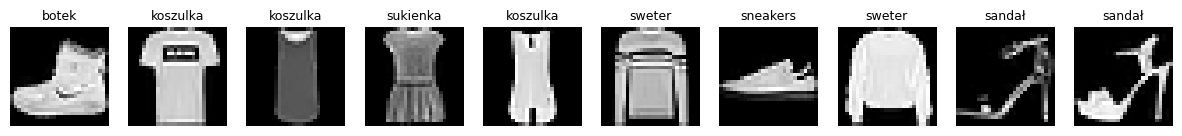

In [3]:
# Twoje rozwiązanie
train_full = datasets.FashionMNIST(root="data", train=True, download=True, transform=transforms.ToTensor())
test_set = datasets.FashionMNIST(root="data", train=False, download=True, transform=transforms.ToTensor())

train_set, val_set = random_split(train_full, [50_000, 10_000], generator=torch.Generator().manual_seed(42))

train_loader = DataLoader(train_set, batch_size=128, shuffle=True)
val_loader = DataLoader(val_set, batch_size=1000)
test_loader = DataLoader(test_set, batch_size=1000)

fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for ax, i in zip(axes, range(10)):
    img, lab = train_full[i]
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(klasy[lab], fontsize=9)
    ax.axis("off")
plt.show()

In [4]:
# TEST
assert len(train_set) == 50_000 and len(val_set) == 10_000 and len(test_set) == 10_000
assert tuple(train_full[0][0].shape) == (1, 28, 28)
print("1 OK")

1 OK


---
## 2. Funkcje uczenia i oceny
Napisz (lub przenieś z wzoru i zrozum!) trzy funkcje:
- `epoka_uczenia(model, loader, optimizer)` – jedna epoka uczenia z `model.train()`,
- `ocen(model, loader)` – zwraca `(strata, accuracy)` z `model.eval()` i `torch.no_grad()`,
- `trenuj(model, epochs=5, lr=1e-3)` – optymalizator Adam; po każdej epoce zapisuje accuracy na train i val w słowniku z kluczami `"train acc"`, `"val acc"` i go zwraca.

In [5]:
# Twoje rozwiązanie
loss_fn = nn.CrossEntropyLoss()

def epoka_uczenia(model, loader, optimizer):
    model.train()
    for xb, yb in loader:
        loss = loss_fn(model(xb), yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

def ocen(model, loader):
    """Zwraca (strata, accuracy) na danym zbiorze."""
    model.eval()
    suma_straty, trafione, n = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            logity = model(xb)
            suma_straty += loss_fn(logity, yb).item() * len(yb)
            trafione += (logity.argmax(dim=1) == yb).sum().item()
            n += len(yb)
    return suma_straty / n, trafione / n

def trenuj(model, epochs=5, lr=1e-3):
    optimizer = optim.Adam(model.parameters(), lr=lr)
    historia = {"train acc": [], "val acc": []}
    start = time.time()
    for e in range(epochs):
        epoka_uczenia(model, train_loader, optimizer)
        historia["train acc"].append(ocen(model, train_loader)[1])
        historia["val acc"].append(ocen(model, val_loader)[1])
        print(f"epoka {e + 1}: train acc {historia['train acc'][-1]:.4f}, val acc {historia['val acc'][-1]:.4f}")
    print(f"czas: {time.time() - start:.0f} s")
    return historia

---
## 3. Model bazowy: regresja softmax
`torch.manual_seed(0)`, potem `model_soft = nn.Sequential(nn.Flatten(), nn.Linear(784, 10))` i `hist_soft = trenuj(model_soft)`.

In [6]:
# Twoje rozwiązanie
torch.manual_seed(0)
model_soft = nn.Sequential(nn.Flatten(), nn.Linear(784, 10))
hist_soft = trenuj(model_soft)

epoka 1: train acc 0.8159, val acc 0.8105
epoka 2: train acc 0.8308, val acc 0.8282
epoka 3: train acc 0.8445, val acc 0.8386
epoka 4: train acc 0.8465, val acc 0.8376
epoka 5: train acc 0.8519, val acc 0.8458
czas: 64 s


In [7]:
# TEST
assert len(hist_soft["val acc"]) == 5
assert 0.78 < hist_soft["val acc"][-1] < 0.88
print("3 OK")

3 OK


---
## 4. Dwie sieci
Przed każdym modelem `torch.manual_seed(0)`:
- `model_maly`: `Flatten → Linear(784, 128) → ReLU → Linear(128, 10)` → `hist_maly`,
- `model_duzy`: `Flatten → Linear(784, 256) → ReLU → Linear(256, 128) → ReLU → Linear(128, 10)` → `hist_duzy`.

Zbierz wyniki trzech modeli w `pd.DataFrame` o nazwie `wyniki` (indeks: `"softmax"`, `"sieć mała"`, `"sieć duża"`; kolumny: `"parametry"`, `"train acc"`, `"val acc"` – wartości po ostatniej epoce) i narysuj krzywe **val acc** wszystkich trzech modeli na jednym wykresie.

epoka 1: train acc 0.8443, val acc 0.8404
epoka 2: train acc 0.8608, val acc 0.8557
epoka 3: train acc 0.8686, val acc 0.8570
epoka 4: train acc 0.8761, val acc 0.8686
epoka 5: train acc 0.8745, val acc 0.8626
czas: 67 s
epoka 1: train acc 0.8492, val acc 0.8410
epoka 2: train acc 0.8627, val acc 0.8615
epoka 3: train acc 0.8855, val acc 0.8724
epoka 4: train acc 0.8831, val acc 0.8725
epoka 5: train acc 0.8974, val acc 0.8817
czas: 74 s
           parametry  train acc  val acc
softmax         7850    0.85194   0.8458
sieć mała     101770    0.87446   0.8626
sieć duża     235146    0.89742   0.8817


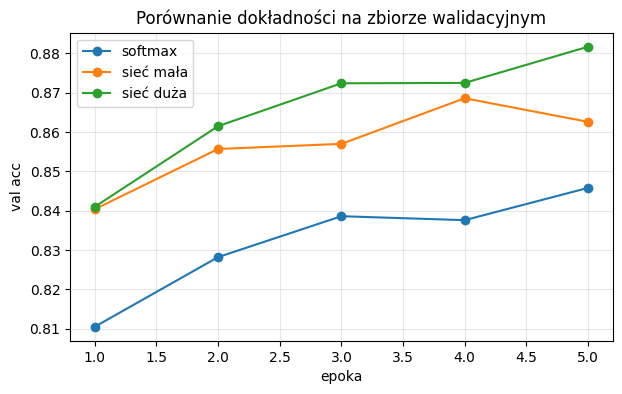

In [8]:
# Twoje rozwiązanie
import pandas as pd

torch.manual_seed(0)
model_maly = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
)
hist_maly = trenuj(model_maly)

torch.manual_seed(0)
model_duzy = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 256),
    nn.ReLU(),
    nn.Linear(256, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
)
hist_duzy = trenuj(model_duzy)

liczba_param = lambda m: sum(p.numel() for p in m.parameters())

wyniki = pd.DataFrame({
    "parametry": [
        liczba_param(model_soft),
        liczba_param(model_maly),
        liczba_param(model_duzy)
    ],
    "train acc": [
        hist_soft["train acc"][-1],
        hist_maly["train acc"][-1],
        hist_duzy["train acc"][-1]
    ],
    "val acc": [
        hist_soft["val acc"][-1],
        hist_maly["val acc"][-1],
        hist_duzy["val acc"][-1]
    ]
}, index=["softmax", "sieć mała", "sieć duża"])

print(wyniki)

fig, ax = plt.subplots(figsize=(7, 4))
for nazwa, h in [("softmax", hist_soft), ("sieć mała", hist_maly), ("sieć duża", hist_duzy)]:
    ax.plot(range(1, 6), h["val acc"], "o-", label=nazwa)
ax.set_xlabel("epoka")
ax.set_ylabel("val acc")
ax.set_title("Porównanie dokładności na zbiorze walidacyjnym")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

In [9]:
# TEST
assert list(wyniki.index) == ["softmax", "sieć mała", "sieć duża"]
assert wyniki.loc["sieć mała", "parametry"] == 101_770 and wyniki.loc["sieć duża", "parametry"] == 235_146
assert wyniki.loc["sieć mała", "val acc"] > wyniki.loc["softmax", "val acc"]
print("4 OK")

4 OK


*Twoja odpowiedź:*
1. Ile zyskuje sieć względem softmaksu na Fashion-MNIST, a ile zyskiwała na MNIST (wzór)? Skąd różnica?
2. Czy duża sieć jest wyraźnie lepsza od małej? Czy 2,3 razy więcej parametrów się opłaca?
3. Porównaj train acc i val acc dla każdego modelu. Gdzie różnica jest największa i co może oznaczać?

---

1. Na Fashion-MNIST sieć zyskuje ok. 1,7-3,6 p.p. na walidacji (od 84,58% dla softmaksu do 86,26% dla sieci małej i 88,17% dla dużej), podczas gdy na prostszym MNIST zysk był większy (ok. 5-6 p.p., z ~92% do ~97,7%). Różnica wynika z tego, że klasy ubrań (np. koszula, koszulka, sweter, płaszcz) są wizualnie bardzo podobne i mają bardziej złożone tekstury oraz kształty niż cyfry, więc sama warstwa ukryta MLP (bez warstw konwolucyjnych) ma ograniczone możliwości ich rozróżniania

2. Duża sieć osiąga wynik lepszy o 1,91 p.p. (88,17% vs 86,26%) i ma stabilniejszy wzrost bez spadku w piątej epoce. Przy czasie treningu dłuższym zaledwie o 8 sekund (74 s vs 66 s) i wciąż niewielkim rozmiarze modelu, zysk jakościowy w pełni uzasadnia użycie większej liczby parametrów

3. Porównanie `train acc` i `val acc`:
- softmax: `train` 85,19% vs `val` 84,58% (różnica 0,61 p.p.)
- sieć mała: `train` 87,45% vs `val` 86,26% (różnica 1,19 p.p.)
- sieć duża: `train` 89,74% vs `val` 88,17% (różnica 1,57 p.p.)

Największa różnica występuje w sieci dużej (1,57 p.p.). Oznacza to początek przeuczenia (overfittingu) - model o większej pojemności zaczyna stopniowo zapamiętywać szczegóły danych treningowych zamiast uczyć się wyłącznie ogólnych cech.

---
## 5. Ocena końcowa i błędy
1. `najlepszy` – nazwa modelu z najwyższym `val acc` w tabeli `wyniki`; `model_koncowy` – ten model.
2. `acc_test` – accuracy na zbiorze **testowym** (jedyny raz, kiedy go używasz).
3. Zbierz predykcje dla całego zbioru testowego (`y_true`, `y_pred` jako tablice NumPy) i narysuj macierz pomyłek z nazwami klas (`ConfusionMatrixDisplay.from_predictions`, `xticks_rotation=45`).
4. Wypisz 3 pary klas (prawdziwa → przewidziana), które model myli najczęściej.

Najlepszy model (wg val acc): sieć duża
Test accuracy: 0.8751


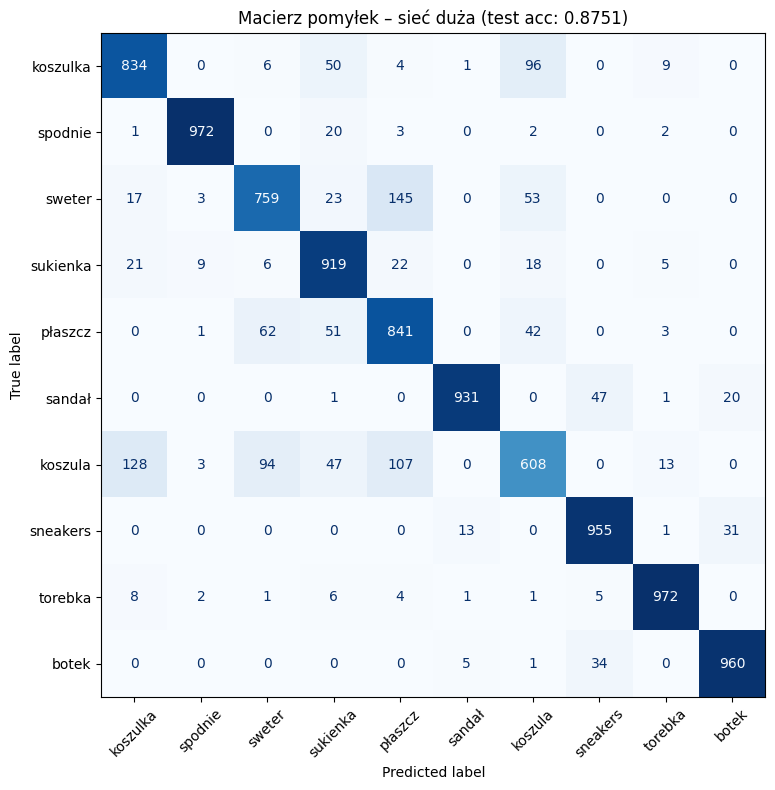


3 najczęstsze pomyłki (prawdziwa -> przewidziana):
sweter -> płaszcz: 145 razy
koszula -> koszulka: 128 razy
koszula -> płaszcz: 107 razy


In [10]:
# Twoje rozwiązanie
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

modele_dict = {
    "softmax": model_soft,
    "sieć mała": model_maly,
    "sieć duża": model_duzy
}

najlepszy = wyniki["val acc"].idxmax()
model_koncowy = modele_dict[najlepszy]

_, acc_test = ocen(model_koncowy, test_loader)
print(f"Najlepszy model (wg val acc): {najlepszy}")
print(f"Test accuracy: {acc_test:.4f}")

# Zbieranie predykcji dla całego zbioru testowego
model_koncowy.eval()
y_true_list, y_pred_list = [], []

with torch.no_grad():
    for xb, yb in test_loader:
        preds = model_koncowy(xb).argmax(dim=1)
        y_true_list.append(yb.numpy())
        y_pred_list.append(preds.numpy())

y_true = np.concatenate(y_true_list)
y_pred = np.concatenate(y_pred_list)

# Macierz pomyłek
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred, display_labels=klasy, xticks_rotation=45, ax=ax, cmap="Blues", colorbar=False
)
ax.set_title(f"Macierz pomyłek – {najlepszy} (test acc: {acc_test:.4f})")
plt.tight_layout()
plt.show()

# 3 najczęstsze pomyłki (prawdziwa -> przewidziana)
cm = confusion_matrix(y_true, y_pred)
np.fill_diagonal(cm, 0)  # zerujemy poprawne klasyfikacje na przekątnej

top3_idx = np.argsort(cm.ravel())[::-1][:3]
print("\n3 najczęstsze pomyłki (prawdziwa -> przewidziana):")
for idx in top3_idx:
    prawdziwa, przewidziana = np.unravel_index(idx, cm.shape)
    liczba = cm[prawdziwa, przewidziana]
    print(f"{klasy[prawdziwa]} -> {klasy[przewidziana]}: {liczba} razy")

In [11]:
# TEST
assert najlepszy == wyniki["val acc"].idxmax()
assert 0.82 < acc_test < 0.92
assert len(y_true) == len(y_pred) == 10_000
print("5 OK")

5 OK


*Twoja odpowiedź:* które klasy model myli najczęściej? Czy człowiek też miałby z nimi kłopot na obrazku 28 × 28? Która klasa jest najłatwiejsza i dlaczego?

---
- Które klasy model myli najczęściej? Model myli przede wszystkim górne części garderoby o podobnym kroju: sweter z płaszczem (145), koszulę z koszulką (128) oraz koszulę z płaszczem (107) (a także koszulkę z koszulą - 96 i koszulę ze swetrem - 94). Widać wyraźnie, że najtrudniejszą ogólną klasą jest koszula (tylko 608/1000 poprawnych predykcji)

- Czy człowiek miałby kłopot na obrazku 28 × 28? Tak. Przy tak niskiej rozdzielczości (784 piksele) i w skali szarości znikają detale decydujące o typie ubrania, takie jak guziki, kołnierzyk, zamek błyskawiczny czy faktura materiału (dzianina swetra vs gładki materiał płaszcza). Sylwetki tych ubrań są niemal identyczne

- Która klasa jest najłatwiejsza i dlaczego? Najłatwiejsze są spodnie (972/1000) oraz torebka (972/1000) (zaraz za nimi botek - 960 i sneakers - 955). Wynika to z ich unikalnego kształtu - spodnie jako jedyne mają charakterystyczne rozwidlenie na dwie nogawki, a torebka ma specyficzną, zwartą bryłę z uchwytem, dzięki czemu nie przypominają żadnej innej kategorii w zbiorze

---
## 6. Dla chętnych
1. Naucz `model_duzy` od nowa przez **15 epok** i narysuj train acc i val acc. Od której epoki krzywe zaczynają się rozjeżdżać? (To przeuczenie – temat następnych zajęć.)
2. Zamień `ReLU` na `Sigmoid` w małej sieci. Jak zmienia się szybkość uczenia?
3. Narysuj 10 obrazów testowych, na których model się pomylił, z podpisem „przewidziane (prawdziwe)”.

epoka 1: train acc 0.8492, val acc 0.8410
epoka 2: train acc 0.8627, val acc 0.8615
epoka 3: train acc 0.8855, val acc 0.8724
epoka 4: train acc 0.8831, val acc 0.8725
epoka 5: train acc 0.8974, val acc 0.8817
epoka 6: train acc 0.8968, val acc 0.8799
epoka 7: train acc 0.9021, val acc 0.8840
epoka 8: train acc 0.9087, val acc 0.8865
epoka 9: train acc 0.9084, val acc 0.8863
epoka 10: train acc 0.9159, val acc 0.8881
epoka 11: train acc 0.9181, val acc 0.8894
epoka 12: train acc 0.9213, val acc 0.8918
epoka 13: train acc 0.9262, val acc 0.8937
epoka 14: train acc 0.9227, val acc 0.8864
epoka 15: train acc 0.9210, val acc 0.8842
czas: 223 s


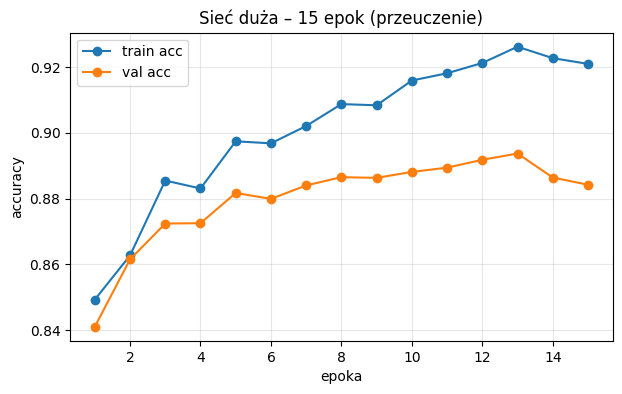

In [12]:
# 6.1
torch.manual_seed(0)
model_duzy_15 = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 256),
    nn.ReLU(),
    nn.Linear(256, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
)
hist_duzy_15 = trenuj(model_duzy_15, epochs=15)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(1, 16), hist_duzy_15["train acc"], "o-", label="train acc")
ax.plot(range(1, 16), hist_duzy_15["val acc"], "o-", label="val acc")
ax.set_xlabel("epoka")
ax.set_ylabel("accuracy")
ax.set_title("Sieć duża – 15 epok (przeuczenie)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

Od której epoki krzywe zaczynają się rozjeżdżać?
- Krzywe zaczynają się wyraźnie rozjeżdżać już od trzeciej epoki (po deugiej epoce wartości są niemal identyczne: 86,27% vs 86,15%, a od trzeciej epoki luka stale rośnie z 1,31 p.p. do 3,68 p.p. w piętnastej epoce). Widać klasyczne przeuczenie (overfitting): train acc rośnie niemal do końca (do 92,62% w trzynastej epoce), podczas gdy val acc rośnie coraz wolniej, a po trzynastej epoce zaczyna wręcz spadać (z 89,37% do 88,42%)

epoka 1: train acc 0.8192, val acc 0.8172
epoka 2: train acc 0.8496, val acc 0.8436
epoka 3: train acc 0.8623, val acc 0.8556
epoka 4: train acc 0.8673, val acc 0.8635
epoka 5: train acc 0.8723, val acc 0.8619
czas: 67 s


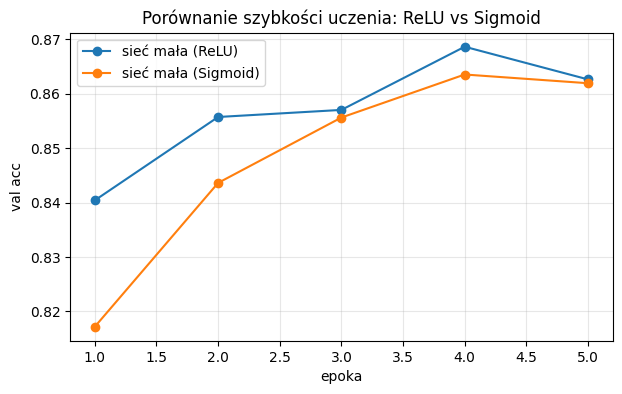

In [13]:
# 6.2 - 5 epok
torch.manual_seed(0)
model_maly_sig = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 128),
    nn.Sigmoid(),
    nn.Linear(128, 10)
)
hist_maly_sig = trenuj(model_maly_sig)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(1, 6), hist_maly["val acc"], "o-", label="sieć mała (ReLU)")
ax.plot(range(1, 6), hist_maly_sig["val acc"], "o-", label="sieć mała (Sigmoid)")
ax.set_xlabel("epoka")
ax.set_ylabel("val acc")
ax.set_title("Porównanie szybkości uczenia: ReLU vs Sigmoid")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

epoka 1: train acc 0.8443, val acc 0.8404
epoka 2: train acc 0.8608, val acc 0.8557
epoka 3: train acc 0.8686, val acc 0.8570
epoka 4: train acc 0.8761, val acc 0.8686
epoka 5: train acc 0.8745, val acc 0.8626
epoka 6: train acc 0.8924, val acc 0.8796
epoka 7: train acc 0.8911, val acc 0.8755
epoka 8: train acc 0.8973, val acc 0.8830
epoka 9: train acc 0.9011, val acc 0.8820
epoka 10: train acc 0.9052, val acc 0.8843
czas: 133 s
epoka 1: train acc 0.8192, val acc 0.8172
epoka 2: train acc 0.8496, val acc 0.8436
epoka 3: train acc 0.8623, val acc 0.8556
epoka 4: train acc 0.8673, val acc 0.8635
epoka 5: train acc 0.8723, val acc 0.8619
epoka 6: train acc 0.8811, val acc 0.8715
epoka 7: train acc 0.8856, val acc 0.8741
epoka 8: train acc 0.8868, val acc 0.8749
epoka 9: train acc 0.8878, val acc 0.8760
epoka 10: train acc 0.8933, val acc 0.8810
czas: 145 s


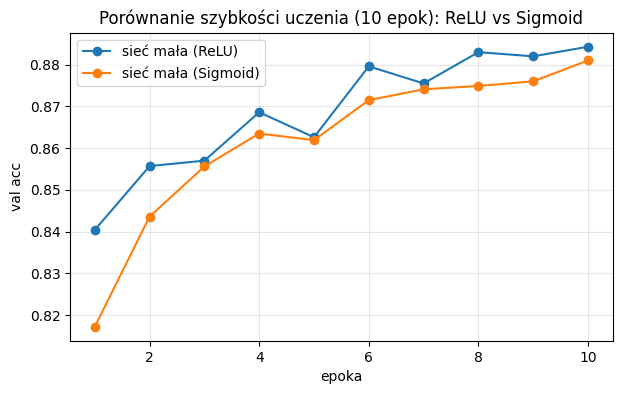

In [14]:
# 6.2 - 10 epok
torch.manual_seed(0)
model_maly_relu_10 = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
)
hist_maly_relu_10 = trenuj(model_maly_relu_10, epochs=10)

torch.manual_seed(0)
model_maly_sig_10 = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 128),
    nn.Sigmoid(),
    nn.Linear(128, 10)
)
hist_maly_sig_10 = trenuj(model_maly_sig_10, epochs=10)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(1, 11), hist_maly_relu_10["val acc"], "o-", label="sieć mała (ReLU)")
ax.plot(range(1, 11), hist_maly_sig_10["val acc"], "o-", label="sieć mała (Sigmoid)")
ax.set_xlabel("epoka")
ax.set_ylabel("val acc")
ax.set_title("Porównanie szybkości uczenia (10 epok): ReLU vs Sigmoid")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

Jak zmienia się szybkość uczenia?
- Z funkcją Sigmoid sieć uczy się wyraźnie wolniej na początku - po pierwszej epoce osiąga val acc 81,72% wobec 84,04% dla ReLU (różnica 2,32 p.p.). Wynika to z mniejszych gradientów funkcji sigmoidalnej (maksymalna pochodna to 0,25 i nasycanie się na krańcach), co spowalnia aktualizację wag na starcie. W krótkim treningu (5 epok) Sigmoid niemal dogania ReLU (86,19% vs 86,26%), jednak na dystansie 10 epok widać, że ReLU utrzymuje stałą przewagę przez cały trening i osiąga wyższą dokładność końcową (88,43% vs 88,10%, a na zbiorze treningowym 90,52% vs 89,33%). Czas obliczeń jest niemal identyczny (134 s vs 139 s dla 10 epok)

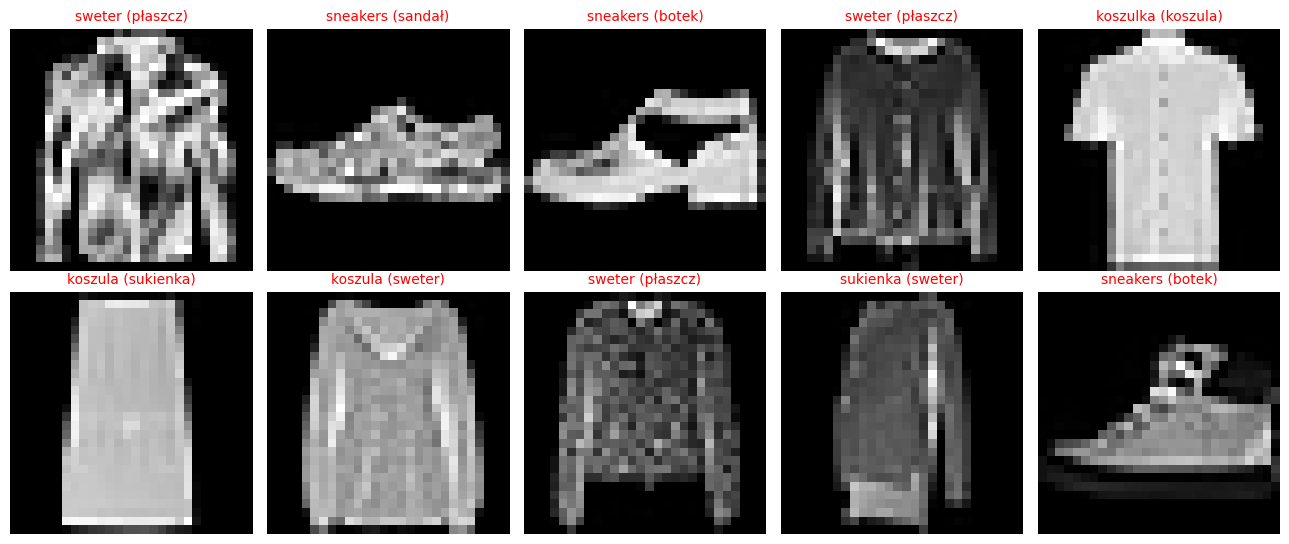

In [15]:
# 6.3
model_koncowy.eval()
obrazy, etykiety = next(iter(test_loader))

with torch.no_grad():
    pred = model_koncowy(obrazy).argmax(dim=1)

bledy = (pred != etykiety).nonzero().squeeze()[:10]

fig, axes = plt.subplots(2, 5, figsize=(13, 5.5))
for ax, i in zip(axes.flat, bledy):
    ax.imshow(obrazy[i].squeeze(), cmap="gray")
    ax.set_title(f"{klasy[pred[i]]} ({klasy[etykiety[i]]})", fontsize=10, color="red")
    ax.axis("off")

plt.tight_layout()
plt.show()